# Part 3B：样本内有效性（In-sample effectiveness）

> 组内工作 notebook。说明文字用中文；**图表、表格的文字用英文**，可以直接放进报告。

## 题目在问什么

把 3A 得到的三组权重**放回估计它们的同一段数据**（1995/01 – 2004/12）上，算出各自实际实现的年化波动率：

- 哪个组合的实现波动率最低、哪个最高？
- 这个顺序是否"符合预期"？结合课上讲的优化内容，为什么会这样？

**直观理解**：权重是用 1995–2004 的数据"量身定做"的，再用同一段数据检验，相当于开卷考试，所以叫**样本内**。3C 会换成 2005–2023 年这段优化器没见过的数据，也就是**样本外**。

## 计算方法

1. 每个月的组合收益 $r_{p,t} = w^\top r_t$，$w$ 固定为 3A 的权重（相当于每月调回目标权重，期间不重新估计）；
2. 年化波动率 = 月收益标准差（样本标准差，ddof = 1）× $\sqrt{12}$，按组内约定用 `utils.annualized_volatility()`。

## 本 notebook 的输出

| 文件 | 内容 |
|---|---|
| `output/tables/tab_3B_insample_vol.csv` | 三个组合及参照组的样本内年化波动率 |
| `output/figures/fig_3B_insample_vol.png` | 报告用柱状图 |

## 目录

1. 环境设置 · 2. 读取数据与 3A 权重 · 3. 样本内组合收益与波动率 · 4. 验证：实现波动率 = 优化时的目标值 · 5. 参照组 · 6. 报告用图表 · 7. 写报告时的要点

## 1. 环境设置

读数据、行业名称和 3A 权重的代码放在同目录的 `part3_common.py` 里，3B–3E 共用，保证各题读到的数据和权重完全一样。

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "part3_common.py").exists()
            or (p / "part3" / "python_source" / "part3_common.py").exists())
if not (HERE / "part3_common.py").exists():
    HERE = HERE / "part3" / "python_source"
sys.path.insert(0, str(HERE))
import part3_common as p3
from part3_common import config, utils, COLS, CN, EN

config.apply_style()
print("项目根目录:", p3.ROOT)
print("种子期    :", config.PERIODS["3_seed"])

项目根目录: /sessions/rcw-01rbcngabsshdzjnayqvw7p6/mnt/Final Project
种子期    : ('1995-01', '2004-12')


## 2. 读取数据与 3A 权重

`weights_3A.pkl` 由 `question_3A.ipynb` 保存。如果报错找不到文件，先运行 3A。

In [2]:
rets = p3.load_industry_returns()
W = p3.load_weights_3A()
seed = utils.select_period(rets, "3_seed")

print(f"全部数据: {rets.index[0]} ~ {rets.index[-1]}，{rets.shape[0]} 个月 × {rets.shape[1]} 个行业")
print(f"样本内  : {seed.index[0]} ~ {seed.index[-1]}，{seed.shape[0]} 个月")
assert seed.shape == (120, 49)
print("\n3A 权重合计（应全为 1）:")
print(W.sum().rename(COLS).round(6).to_string())

全部数据: 1995-01 ~ 2023-07，343 个月 × 49 个行业
样本内  : 1995-01 ~ 2004-12，120 个月

3A 权重合计（应全为 1）:
Min-var (shorts allowed)    1.0
Min-var (long-only)         1.0
Inverse volatility          1.0


## 3. 样本内组合收益与年化波动率

In [3]:
R_in = p3.portfolio_returns(seed, W)               # 120 × 3 的月度组合收益
vol_in = R_in.apply(utils.annualized_volatility)

res = pd.DataFrame({
    "年化波动率": vol_in,
    "排名（1 = 最低）": vol_in.rank().astype(int),
}).rename(index=COLS).sort_values("年化波动率")
res.style.format({"年化波动率": "{:.2%}"})

,年化波动率,排名（1 = 最低）
Min-var (shorts allowed),7.59%,1
Min-var (long-only),10.32%,2
Inverse volatility,13.99%,3


## 4. 验证：实现波动率 = 优化时的目标值

样本内有一个"必然"的结果：协方差矩阵 $\hat\Sigma$ 就是用这 120 个月的数据估计的，而组合月收益的样本方差恰好等于 $w^\top\hat\Sigma w$。所以：

$$
\underbrace{\text{std}(r_{p,t})\times\sqrt{12}}_{\text{样本内实现波动率}}
\;=\;
\underbrace{\sqrt{w^\top\hat\Sigma w}\times\sqrt{12}}_{\text{3A 优化时的目标值}}
$$

这意味着样本内的排序在数学上是**被保证的**：

- 可做空最小方差 = 所有满仓组合里方差最小的 → 一定最低；
- 只做多最小方差 = 多了 $w\ge0$ 约束 → 只会更高，但它是所有"只做多"组合里最低的；
- 逆波动率也是一个只做多的满仓组合 → 不可能比只做多最小方差更低。

下面用数字确认。

In [4]:
Sigma = seed.cov()
ex_ante = pd.Series({k: np.sqrt(W[k] @ Sigma @ W[k] * 12) for k in W.columns})
check = pd.DataFrame({"实现波动率 std×√12": vol_in, "目标值 √(w'Σw)×√12": ex_ante})
check["差异"] = check.iloc[:, 0] - check.iloc[:, 1]
print(check.rename(index=COLS).to_string(float_format=lambda v: f"{v:.6%}" if abs(v) > 1e-9 else f"{v:.1e}"))
assert np.allclose(vol_in, ex_ante, atol=1e-12)
assert vol_in["mv_short"] <= vol_in["mv_long_only"] <= vol_in["inverse_vol"]
print("\n两者完全一致 ✓；排序 可做空 ≤ 只做多 ≤ 逆波动率 ✓")

                          实现波动率 std×√12  目标值 √(w'Σw)×√12       差异
Min-var (shorts allowed)      7.586112%        7.586112%  5.6e-17
Min-var (long-only)          10.315594%       10.315594%  0.0e+00
Inverse volatility           13.988876%       13.988876% -2.8e-17

两者完全一致 ✓；排序 可做空 ≤ 只做多 ≤ 逆波动率 ✓


## 5. 参照组（题目没要求，用来给数字一个尺度）

只看三个数字，读者很难判断"低"到什么程度。这里加两个同一数据、同一时期的参照：

- **49 个行业等权组合**：完全不考虑风险的"什么都不做"方案；
- **单个行业里波动率最低的那个**：如果只买一个最稳的行业，波动率是多少。三个组合如果都比它低，就说明分散化确实起了作用。

不想放进报告的话，把下面的 `SHOW_REFERENCE` 改成 `False` 再重跑即可，图会只剩三个组合。

In [5]:
SHOW_REFERENCE = True

ind_vol = seed.apply(utils.annualized_volatility)
low_ind = ind_vol.idxmin()
ew = seed.mean(axis=1)                                # 等权，每月调回 1/49
ref = pd.Series({
    "Equal weight (49 industries)": utils.annualized_volatility(ew),
    f"Lowest-vol single industry ({EN[low_ind]})": ind_vol[low_ind],
})
print("参照组样本内年化波动率：")
print(ref.to_string(float_format=lambda v: f"{v:.2%}"))
print(f"\n单个行业波动率：中位数 {ind_vol.median():.1%}，最低 {ind_vol.min():.1%}（{low_ind} {CN[low_ind]}），"
      f"最高 {ind_vol.max():.1%}（{ind_vol.idxmax()} {CN[ind_vol.idxmax()]}）")

table = pd.concat([vol_in.rename(index=COLS), ref])
table.index.name = "Portfolio"
table = table.to_frame("In-sample annualized volatility (Jan 1995 - Dec 2004)")
table["Type"] = ["3A portfolio"] * 3 + ["Reference"] * 2
path = utils.save_table(table, "tab_3B_insample_vol", float_format="%.6f")
print("\nCSV →", path.relative_to(p3.ROOT))
table.style.format({table.columns[0]: "{:.2%}"})

参照组样本内年化波动率：
Equal weight (49 industries)                 14.63%
Lowest-vol single industry (Food products)   15.18%

单个行业波动率：中位数 21.9%，最低 15.2%（Food 食品），最高 44.2%（Coal 煤炭）

CSV → output/tables/tab_3B_insample_vol.csv


,In-sample annualized volatility (Jan 1995 - Dec 2004),Type
Portfolio,,
Min-var (shorts allowed),7.59%,3A portfolio
Min-var (long-only),10.32%,3A portfolio
Inverse volatility,13.99%,3A portfolio
Equal weight (49 industries),14.63%,Reference
Lowest-vol single industry (Food products),15.18%,Reference


## 6. 报告用图表

横向柱状图，从低到高排列；三个组合用组内统一的颜色，参照组用灰色。柱子末端标注数值，图下注明数据来源、时期和计算方法。

PNG → output/figures/fig_3B_insample_vol.png


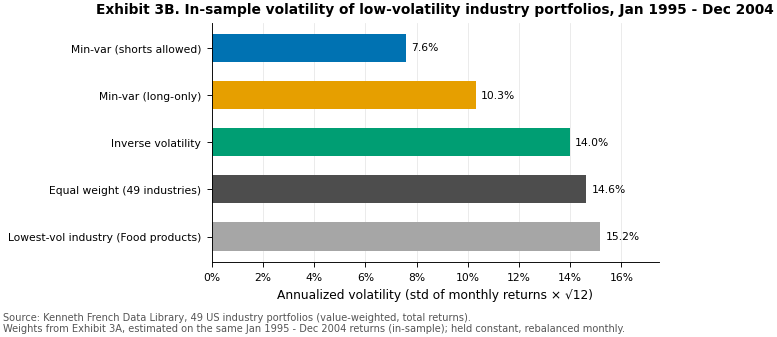

In [6]:
labels = [p3.SHORT_LABELS[k].replace("\n", " ") for k in W.columns]
vals = list(vol_in.to_numpy())
colors = [p3.PF_COLORS[k] for k in W.columns]
if SHOW_REFERENCE:
    labels += ["Equal weight (49 industries)", f"Lowest-vol industry ({EN[low_ind]})"]
    vals += list(ref.to_numpy())
    colors += [config.COLOR_MARKET, "#A6A6A6"]
order = np.argsort(vals)[::-1]          # 最低的画在最上面

fig, ax = utils.new_fig("full")
y = np.arange(len(vals))
ax.barh(y, np.array(vals)[order], color=np.array(colors)[order], height=0.6)
ax.set_yticks(y, np.array(labels)[order])
for yi, v in zip(y, np.array(vals)[order]):
    ax.text(v + 0.002, yi, f"{v:.1%}", va="center", fontsize=config.FONT_SMALL)
ax.set_xlim(0, max(vals) * 1.15)
utils.percent_axis(ax, "x")
ax.set_xlabel("Annualized volatility (std of monthly returns × √12)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.set_title("Exhibit 3B. In-sample volatility of low-volatility industry portfolios, Jan 1995 - Dec 2004")
src = (p3.SOURCE_FF49 + "\nWeights from Exhibit 3A, estimated on the same Jan 1995 - Dec 2004 returns "
       "(in-sample); held constant, rebalanced monthly.")
path = utils.save_fig(fig, "fig_3B_insample_vol", source=src)
print("PNG →", path.relative_to(p3.ROOT))
plt.show()

## 7. 写报告时的要点

> 下面的数字来自本 notebook 的运行结果（数据固定，重跑结果不变）。

### 结果速览（1995/01 – 2004/12，样本内）

| 组合 | 年化波动率 | 排名 |
|---|---|---|
| 最小方差（可做空） | **7.6%** | 1（最低） |
| 最小方差（只做多） | 10.3% | 2 |
| 逆波动率 | 14.0% | 3（最高） |
| *参照：49 个行业等权* | *14.6%* | – |
| *参照：波动率最低的单个行业（食品）* | *15.2%* | – |

### 可以写进报告的观察

1. **顺序完全符合预期**：可做空 < 只做多 < 逆波动率。而且在样本内，这个顺序是**数学上必然**的：
    - 可做空最小方差是所有满仓组合里方差最小的；
    - 加上 $w \ge 0$ 约束后，最小值只会更高；
    - 逆波动率也是一个只做多的满仓组合，不可能比只做多最小方差更低。
2. **实现波动率与优化目标值完全相等**（第 4 节验证，差异约 $10^{-17}$）。原因是协方差矩阵就是用这 120 个月估计的，所以样本内的"检验"其实只是把优化目标重新算了一遍，本身不能证明组合有效。
3. **用到的信息越多，样本内波动越低**：
    - 逆波动率只用了各行业自己的波动，不考虑相关性，只比等权（14.6%）低 0.6 个百分点；
    - 只做多最小方差利用了相关性，降到 10.3%；
    - 可做空版本还能用空头对冲，降到 7.6%，大约是等权组合的一半。
4. **三个组合都低于最稳的单个行业（食品，15.2%）**，说明分散化本身带来了风险下降，不只是因为挑中了低波动行业。
5. **为什么不能只看这个结果（课上的"优化放大估计误差"）**：
    - 49×49 的协方差矩阵只用 120 个月估计，误差很大（条件数约 711）；
    - 优化器会专门押注那些"碰巧"显得波动低、相关性低的行业组合，把噪音当成规律。可做空组合 41% 的印刷出版多头、−32% 的商业服务空头就是例子；
    - 用的信息越多，被高估得越厉害。所以可做空组合的 7.6% 最"好看"，也最可能有水分；
    - 而且现实中没人能在 1995 年就知道这组权重，样本内结果本身就带有前视偏差。真正的检验要看 3C 的样本外结果。

### 英文写法参考（可改写进报告）

> In-sample (Jan 1995 – Dec 2004), the minimum-variance portfolio with shorts allowed has the lowest realized volatility (7.6% p.a.), followed by the long-only minimum-variance portfolio (10.3%) and the inverse-volatility portfolio (14.0%); an equally weighted portfolio of all 49 industries has 14.6%. This ordering is exactly as expected and in fact guaranteed: the realized in-sample volatility equals the optimizer's objective, because the covariance matrix was estimated on these same returns. Each additional constraint (no shorting) or simplification (ignoring correlations) can only raise the minimum attainable in-sample variance. However, the in-sample result overstates the true risk reduction: with only 120 monthly observations to estimate a 49 × 49 covariance matrix, the optimizer exploits estimation error ("error maximization"), most aggressively when shorting is allowed. Out-of-sample performance (3C) is the relevant test.

### 备注

- 参照组（等权、最低波动单个行业）不是题目要求的。不想放的话把第 5 节的 `SHOW_REFERENCE` 改成 `False` 再重跑；
- 年化波动率按组内约定计算：月收益样本标准差 × √12。